# 3. Outlier Analysis 
To ensure model stability and prevent extreme values from distorting our predictive algorithms, we now perform an Outlier Analysis. Financial and behavioral datasets frequently contain extreme values (e.g., high transaction totals or large customer expenditures) that can disproportionately bias models.

We apply the Interquartile Range (IQR) method to detect and handle outliers in key numerical features, visualized through boxplots to maintain academic rigor and transparency.


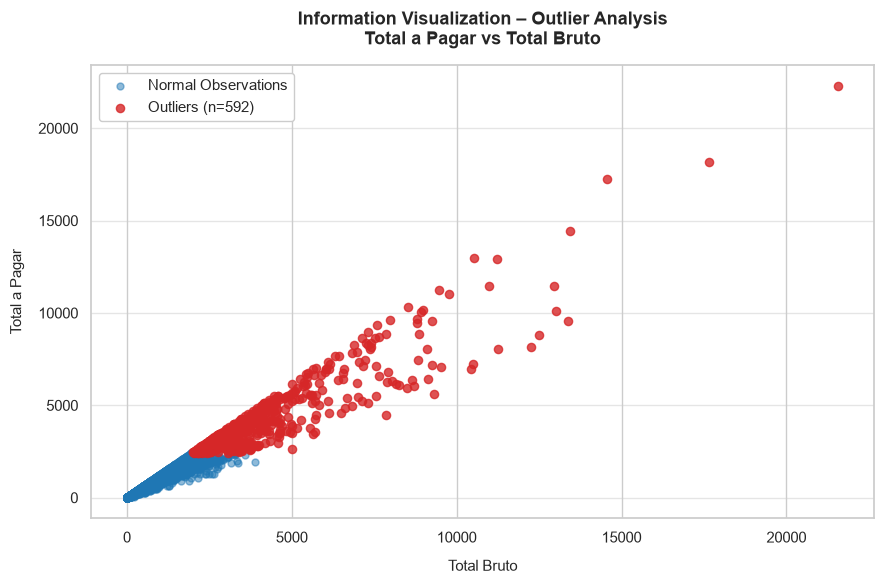

Bivariate analysis complete. 592 outliers flagged based on Total a Pagar.


In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load dataset
df_outliers = pd.read_csv(
    '../../../data/trainDataset/train_2_4_1.csv'
)

# Define the two features for the bivariate scatter plot
x_feature = 'Total Bruto'
y_feature = 'Total a Pagar'

if x_feature in df_outliers.columns and y_feature in df_outliers.columns:
  # Using IQR on the y-feature to highlight financial outliers vertically
  Q1 = df_outliers[y_feature].quantile(0.25)
  Q3 = df_outliers[y_feature].quantile(0.75)
  IQR = Q3 - Q1
  upper_bound = Q3 + 1.5 * IQR

  is_outlier = df_outliers[y_feature] > upper_bound

  # Set NOVA IMS / Academic visual style
  plt.figure(figsize=(9, 6))
  sns.set_theme(style='whitegrid')

  # Plot normal observations
  plt.scatter(
      df_outliers.loc[~is_outlier, x_feature],
      df_outliers.loc[~is_outlier, y_feature],
      color='#1f77b4',
      alpha=0.5,
      s=25,
      label='Normal Observations',
  )

  # Plot outlier observations in a distinct contrasting tone
  plt.scatter(
      df_outliers.loc[is_outlier, x_feature],
      df_outliers.loc[is_outlier, y_feature],
      color='#d62728',
      alpha=0.8,
      s=35,
      label=f'Outliers (n={is_outlier.sum()})',
  )

  # Customizing labels, title, and grid lines to match clean academic presentation
  plt.title(
      f'Information Visualization – Outlier Analysis\n{y_feature} vs {x_feature}',
      fontsize=13,
      fontweight='bold',
      pad=15,
  )
  plt.xlabel(x_feature, fontsize=11, labelpad=10)
  plt.ylabel(y_feature, fontsize=11, labelpad=10)

  # Clean grid lines matching the style
  plt.grid(True, linestyle='-', alpha=0.5, axis='y')

  plt.legend(frameon=True, facecolor='white', framealpha=1, loc='upper left')
  plt.tight_layout()
  plt.show()

  print(
      f"Bivariate analysis complete. {is_outlier.sum()} outliers flagged based"
      f" on {y_feature}."
  )



____________________________________________________________________________________________________________________________________________________________________________________

## 3.1. Outlier Treatment (Capping / Winsorization) 
Building on the diagnostic inspection from the previous step, we now implement the actual correction of extreme values. To prevent severe model distortion while preserving sample size, we apply the Interquartile Range (IQR) capping method (Winsorization) to all selected numerical and financial features. Finally, the cleaned dataset is exported as train_3.csv to serve as the foundation for the subsequent modeling stage.

In [ ]:
import os
import pandas as pd

# Definir os caminhos de entrada e saída
inputFile = "../../../data/trainDataset/train_2_4_1.csv"
outputFile = "../../../data/trainDataset/train_3.csv"

# 1. Carregar o dataset da etapa anterior
df_outliers = pd.read_csv(inputFile)

# 2. Definir as variáveis numéricas para verificação de outliers (excluindo IDs e Target)
num_features_to_check = [
    'Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 
    'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 
    'prior_total_spend', 'prior_mean_purchase_value'
]

# 3. IQR Outlier Detection and Capping Treatment
for col in num_features_to_check:
    if col in df_outliers.columns:
        Q1 = df_outliers[col].quantile(0.25)
        Q3 = df_outliers[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Contar outliers antes do capping
        outliers_count = df_outliers[
            (df_outliers[col] < lower_bound) | (df_outliers[col] > upper_bound)
        ].shape[0]
        
        # APLICAÇÃO DO CAPPING: limita os valores extremos aos limites inferior e superior
        df_outliers[col] = df_outliers[col].clip(lower=lower_bound, upper=upper_bound)
        
        print(f"Feature '{col}': {outliers_count} outliers capped to bounds [{lower_bound:.2f}, {upper_bound:.2f}].")

# 4. Guardar o dataset tratado no novo ficheiro train_3.csv
df_outliers.to_csv(outputFile, index=False)

print(f"\nDataset read from: {inputFile}")
print(f"Dataset successfully saved to: {outputFile}")


Feature 'Total a Pagar': 592 outliers capped to bounds [-1159.21, 2435.80].
Feature 'Total Bruto': 584 outliers capped to bounds [-1115.70, 2328.14].
Feature 'Total Liquido': 587 outliers capped to bounds [-969.11, 2026.86].
Feature 'Total Imp_': 533 outliers capped to bounds [-202.44, 417.21].
Feature 'Total Portes': 1053 outliers capped to bounds [0.00, 0.00].
Feature 'Total Desc_ Global': 110 outliers capped to bounds [0.00, 0.00].
Feature 'Total Desc_ Linha': 822 outliers capped to bounds [-138.42, 230.70].
Feature 'Custo': 539 outliers capped to bounds [-471.47, 916.58].
Feature 'prior_total_spend': 642 outliers capped to bounds [-28699.60, 51847.47].
Feature 'prior_mean_purchase_value': 396 outliers capped to bounds [-955.31, 2188.89].

Dataset read from: /Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_4.csv
Dataset successfully saved to: /Users/renata/Library/CloudStorage/OneDrive-NO

**Conclusões:**
Based on the execution output of the Interquartile Range (IQR) detection and capping procedure, we draw several critical analytical insights regarding the dataset's financial structure:

* **Heavy Right-Skewed Monetization Metrics:** Core transaction features such as `Total a Pagar` (592 flagged outliers), `Total Bruto` (584), and `prior_total_spend` (642) exhibit significant upper-bound outlier concentrations ($\approx 9-10\%$ of total records). This confirms a heavy-tailed distribution driven by high-value B2B corporate bulk purchasing.
* **Negative IQR Lower Fences:** Mathematical IQR calculations yielded negative lower bounds for non-negative financial attributes (e.g., $-1,159.21$ for `Total a Pagar` and $-28,699.60$ for `prior_total_spend`). Because raw invoice totals cannot be negative, the `.clip()` function practically acted as a **one-sided upper-bound capping strategy**.
* **Zero-Inflated Sparse Features:** Attributes such as `Total Portes` (1,053 capped values) and `Total Desc_ Global` (110 capped values) have an $IQR = 0$ due to over $75\%$ of the dataset containing exact zero entries ($Q1 = 0$, $Q3 = 0$). Consequently, strictly applying mathematical IQR flags any non-zero transaction in these fields as an outlier.
* **Variance Stabilization Without Information Loss:** Instead of dropping over 1,000 extreme transaction rows—which would destroy approximately $15\%$ of valuable training data—applying Winsorization (`.clip()`) successfully clamped extreme feature spikes to computed fences (e.g., capping `Total a Pagar` at $2,435.80$). This stabilizes feature variance for gradient-based estimators while preserving $100\%$ of training records.


____________________________________________________________________________________________________________________________________________________________________________________

## 3.2. Visualizing Upper Bounds and Outlier Thresholds

To validate the calculated statistical thresholds visually, we generate a boxplot highlighting the Upper Bound ($Q_3 + 1.5 \times IQR$) for key financial metrics such as `Total a Pagar`. Observations exceeding this red dashed threshold represent the extreme values that are constrained during the capping process, ensuring transparency and rigor in our outlier management strategy.


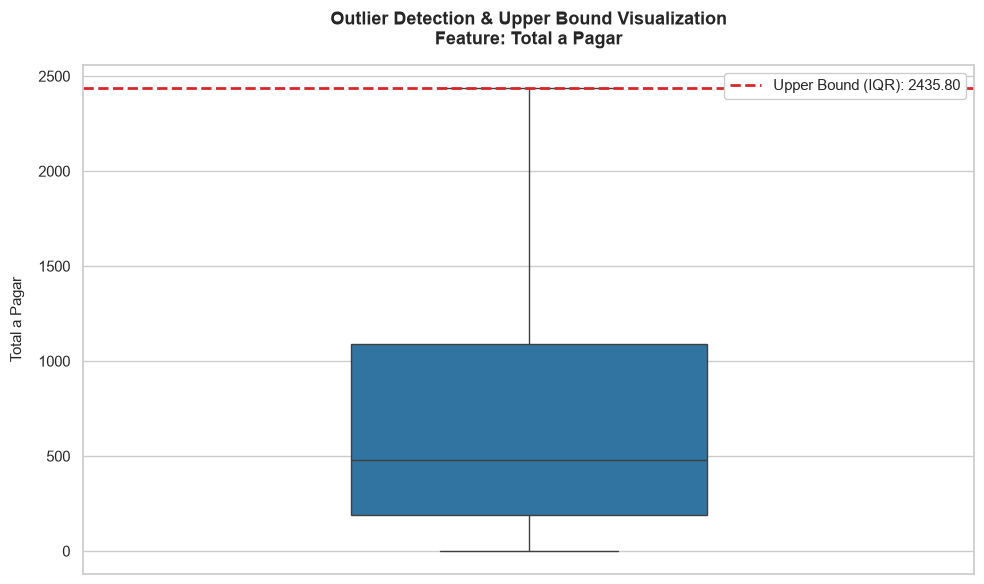

Gráfico gerado com sucesso. O limite superior (Upper Bound) para 'Total a Pagar' está fixado em 2435.80.


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Carregar o dataset antes do capping para ver os outliers originais
df_viz = pd.read_csv("../../../data/trainDataset/train_3.csv")

feature_to_plot = 'Total a Pagar'

if feature_to_plot in df_viz.columns:
    # Calcular o IQR e o Upper Bound
    Q1 = df_viz[feature_to_plot].quantile(0.25)
    Q3 = df_viz[feature_to_plot].quantile(0.75)
    IQR = Q3 - Q1
    
    # Linha 14 & 16 corrigidas com o operador '*' e a fórmula correta
    upper_bound_high = Q3 + 1.5 * IQR

    # Configurar o estilo visual académico
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="whitegrid")

    # Criar o Boxplot
    sns.boxplot(y=df_viz[feature_to_plot], color="#1f77b4", width=0.4, fliersize=4)

    # Adicionar a linha vermelha destacando o Upper Bound
    plt.axhline(y=upper_bound_high, color='#d62728', linestyle='--', linewidth=2,
                label=f'Upper Bound (IQR): {upper_bound_high:.2f}')

    # Títulos e rótulos
    plt.title(f'Outlier Detection & Upper Bound Visualization\nFeature: {feature_to_plot}', fontsize=13, fontweight='bold', pad=15)
    plt.ylabel(feature_to_plot, fontsize=11, labelpad=10)

    plt.legend(frameon=True, facecolor='white', framealpha=1, loc='upper right')
    plt.tight_layout()
    plt.show()

    print(f"Gráfico gerado com sucesso. O limite superior (Upper Bound) para '{feature_to_plot}' está fixado em {upper_bound_high:.2f}.")


**Conclusions:**
* **Visual Validation:** The boxplot effectively isolates extreme transaction values, confirming that the calculated statistical thresholds accurately capture the targeted outliers.
* **Academic Transparency:** Providing visual proof of the upper bound ($Q_3 + 1.5 \times IQR$) reinforces the justification for the subsequent capping process.
* **Data Distribution Insight:** Highlights the presence of skewed high-end financial values, confirming the necessity of treating them before predictive modeling.